# 05 · ¿Por qué no mejora más? Techo de los datos y razones de la salida
**Proyecto final · Análisis de datos, BI y aprendizaje computacional**

El modelo ordena bien la parte alta de la lista pero su poder global es moderado (ROC-AUC ≈ 0,66–0,70). Esta etapa responde con evidencia las preguntas que un jurado haría:

1. **¿Hay un techo en los datos o es culpa del modelo?** (capas de información, curva de aprendizaje, efecto del pago anticipado)
2. **¿Por qué se van los suscriptores nuevos?** (producto, temporada, activación, descuento; ¿necesidad puntual o falta de valor?)
3. **¿Qué se intentó y qué resultado dio cada intento?**
4. **¿Qué preguntas siguen abiertas y cómo se responderían?**

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore")
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OrdinalEncoder
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score

RAIZ = Path("..").resolve(); sys.path.append(str(RAIZ))
from src import features
PROC = RAIZ / "data" / "processed"; FIG = RAIZ / "resultados" / "figuras"; FIG.mkdir(parents=True, exist_ok=True)
AZUL, ROJO, GRIS = "#2F6DB5", "#B3261E", "#8A94A0"
sns.set_theme(style="whitegrid"); pd.set_option("display.width", 200, "display.max_columns", 60)

snap = pd.read_csv(PROC / "fact_snapshot_mensual.csv", parse_dates=["fecha"])
ciclos = pd.read_csv(PROC / "fact_ciclo.csv", dtype={"productoid": str, "ordenid": str},
                     parse_dates=["ciclo_inicio", "ciclo_fin", "fecha_pago", "inicio_renovacion", "fecha_pago_renovacion"])
CAT = features.CAT

def auc_modelo(tr, te, cols):
    cat = [c for c in CAT if c in cols]
    X = lambda d: d[cols].assign(**{k: d[k].astype(str) for k in cat})
    m = make_pipeline(ColumnTransformer([("c", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), cat)], remainder="passthrough"),
                      HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, max_depth=5, min_samples_leaf=40, l2_regularization=1.0, random_state=0))
    m.fit(X(tr), tr["churn90"])
    return roc_auc_score(te["churn90"], m.predict_proba(X(te))[:, 1])

def particion(b):
    return b[b["ciclo_fin"] <= "2026-01-31"], b[(b["ciclo_fin"] >= "2026-05-01") & (b["ciclo_fin"] <= "2026-07-31")]
base = features.base_horizonte(snap, ciclos, 60)
tr, te = particion(base); COLS = features.columnas_modelo(base)
print(f"Entrenamiento: {len(tr):,} ciclos · prueba: {len(te):,} ciclos (vencimientos may–jul 2026, observados a 60 días)")

Entrenamiento: 57,744 ciclos · prueba: 3,872 ciclos (vencimientos may–jul 2026, observados a 60 días)


## 1. ¿Hay un techo en los datos?

### 1.1 Capas de información
Se agrega información por capas y se mide cuánto sube el ROC-AUC en la prueba. Si cada capa suma poco y la última ya casi no mueve, el límite está en lo que los datos pueden decir.

In [2]:
ctx = ["tipo_entrada", "productoid", "prev_tipo_entrada", "ciclos_previos", "numero_ciclo", "duracion_dias", "duracion_extra",
       "mes_vencimiento", "dias_desde_primer_ciclo", "regalos_previos"]
pagos = ["pago_vs_inicio", "prev_pago_vs_inicio", "prev_dias_hasta_renovacion", "prev_duracion"]
comp = [c for c in COLS if c not in ctx + pagos and c not in CAT]
capas = {"1 · solo tipo de entrada y producto": ["tipo_entrada", "productoid"],
         "2 · + historial y contexto del ciclo": ctx,
         "3 · + cómo pagó antes": ctx + pagos,
         "4 · + comportamiento (uso, cupones, compras)": ctx + pagos + comp}
capa_auc = pd.Series({k: auc_modelo(tr, te, v) for k, v in capas.items()}, name="ROC-AUC").round(3)
tabla_capas = capa_auc.to_frame(); tabla_capas["aporte de la capa"] = capa_auc.diff().round(3)
tabla_capas

,ROC-AUC,aporte de la capa
1 · solo tipo de entrada y producto,0.589,NaN
2 · + historial y contexto del ciclo,0.617,0.028
3 · + cómo pagó antes,0.649,0.032
"4 · + comportamiento (uso, cupones, compras)",0.682,0.033


### 1.2 Curva de aprendizaje: ¿faltan datos o falta información?
Si con más ciclos de entrenamiento el modelo mejorara mucho, el problema sería la cantidad. Si se aplana, el problema es **qué se mide**, no cuánto.

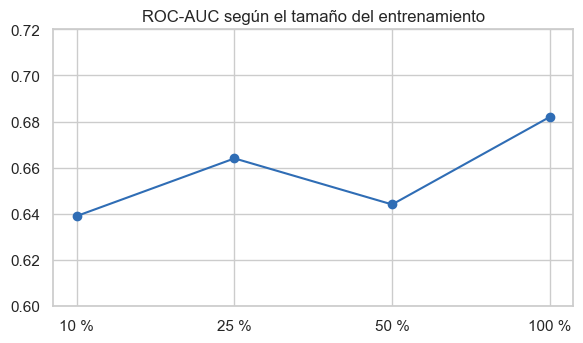

,ROC-AUC
"10 % (5,774)",0.639
"25 % (14,436)",0.664
"50 % (28,872)",0.644
"100 % (57,744)",0.682


In [3]:
res = {}
for frac in (0.1, 0.25, 0.5, 1.0):
    res[frac] = auc_modelo(tr.sample(frac=frac, random_state=0) if frac < 1 else tr, te, COLS)
curva = pd.Series(res, name="ROC-AUC").round(3); curva.index = [f"{int(f*100)} % ({int(len(tr)*f):,})" for f in curva.index]
fig, ax = plt.subplots(figsize=(6, 3.6)); ax.plot(range(len(curva)), curva.values, marker="o", color=AZUL)
ax.set_xticks(range(len(curva))); ax.set_xticklabels([i.split(" ")[0] + " %" for i in curva.index]); ax.set_ylim(0.6, 0.72)
ax.set_title("ROC-AUC según el tamaño del entrenamiento"); plt.tight_layout(); plt.savefig(FIG / "techo_curva_aprendizaje.png", dpi=130); plt.show()
curva.to_frame()

### 1.3 El efecto del pago anticipado: por qué otros modelos "se ven" mejores
Un modelo que incluye a quienes **ya pagaron** la renovación y usa esa marca como variable parece muy bueno cerca del vencimiento, pero está "prediciendo" algo que ya ocurrió. Se comparan tres versiones en la misma prueba.

In [4]:
filas = []
for meses, dias in [(4, 120), (2, 60), (1, 30)]:
    b_ex = features.base_horizonte(snap, ciclos, dias)
    b_in = features.base_horizonte(snap, ciclos, dias, excluir_pagados=False)
    cols = features.columnas_modelo(b_ex)
    a, t1 = particion(b_ex); a2, t2 = particion(b_in)
    filas.append({"meses antes": meses, "ya habían pagado": f"{t2['pago_anticipado'].mean():.0%}",
                  "AUC excluyéndolos (este proyecto)": auc_modelo(a, t1, cols),
                  "AUC incluyéndolos, sin marca": auc_modelo(a2, t2, cols),
                  "AUC incluyéndolos + marca de pago": auc_modelo(a2, t2, cols + ["pago_anticipado"])})
pd.DataFrame(filas).set_index("meses antes").round(3)

,ya habían pagado,AUC excluyéndolos (este proyecto),"AUC incluyéndolos, sin marca",AUC incluyéndolos + marca de pago
meses antes,,,,
4,3%,0.674,0.652,0.677
2,9%,0.682,0.663,0.734
1,15%,0.700,0.674,0.813


### 1.4 Lo que el modelo no puede ver
| Información que no está en los datos | Por qué importaría |
|---|---|
| Precio pagado y descuento real por plan | Mucho descuento: el precio explica la decisión de renovar |
| Motivo de compra (declaración, fecha límite, curiosidad) | Distingue necesidad puntual de necesidad recurrente |
| Motivo de cancelación o de no renovación | Es la etiqueta "por qué", no solo el "si" |
| Satisfacción, calidad percibida, soporte recibido | Variables de valor percibido |
| Competencia, cambio de empleo o de cliente del contador | Factores externos al comportamiento en la plataforma |
| Contactos comerciales antes de febrero de 2026 | Sin histórico no se puede aprender el efecto |
| Fotos mensuales del 41 % de los ciclos | El KPI solo guarda a los suscriptores activos desde 2024 |

## 2. ¿Por qué se van los suscriptores nuevos?
Se analizan las altas nuevas (tipo de entrada `NUEVA`, producto principal, ya cerradas).

Altas nuevas con resultado conocido: 22,216 · churn 68.8%


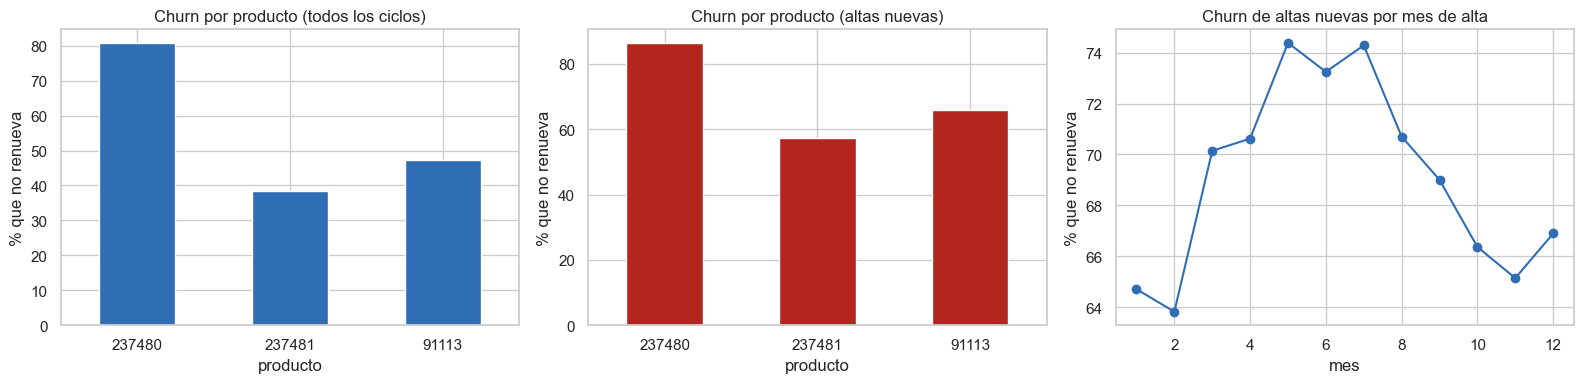

,ciclos,churn,churn altas nuevas,altas nuevas
productoid,,,,
237480,10292,0.806,0.863,5136
237481,19787,0.384,0.573,5254
91113,44225,0.473,0.660,11725


In [5]:
nuevas = ciclos[(ciclos["madura"]) & (ciclos["tipo_entrada"] == "NUEVA") & (ciclos["es_regalo"] == 0) & (ciclos["grupo_producto"] == "Principal")].copy()
print(f"Altas nuevas con resultado conocido: {len(nuevas):,} · churn {nuevas['churn90'].mean():.1%}")
nuevas["mes_alta"] = nuevas["ciclo_inicio"].dt.month
prod = ciclos[ciclos["madura"]].groupby("productoid").agg(ciclos=("churn90", "size"), churn=("churn90", "mean")).query("ciclos > 500")
prod_nuevas = nuevas.groupby("productoid")["churn90"].agg(["mean", "size"]).query("size > 300")

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
(prod["churn"] * 100).plot.bar(ax=ax[0], color=AZUL); ax[0].set_title("Churn por producto (todos los ciclos)"); ax[0].set_xlabel("producto"); ax[0].tick_params(axis="x", rotation=0)
(prod_nuevas["mean"] * 100).plot.bar(ax=ax[1], color=ROJO); ax[1].set_title("Churn por producto (altas nuevas)"); ax[1].set_xlabel("producto"); ax[1].tick_params(axis="x", rotation=0)
(nuevas.groupby("mes_alta")["churn90"].mean() * 100).plot(ax=ax[2], marker="o", color=AZUL); ax[2].set_title("Churn de altas nuevas por mes de alta"); ax[2].set_xlabel("mes")
for a in ax: a.set_ylabel("% que no renueva")
plt.tight_layout(); plt.savefig(FIG / "nuevas_producto_temporada.png", dpi=130); plt.show()
pd.concat([prod.round(3), prod_nuevas.rename(columns={"mean": "churn altas nuevas", "size": "altas nuevas"}).round(3)], axis=1)

### 2.1 Activación: ¿usan la plataforma al comprar?
Se miran las altas nuevas con fotos mensuales en sus primeros 75 días: cuánto tardaron en ingresar por primera vez y cuántos días navegaron en los primeros dos meses.

Altas nuevas con fotos en sus primeros 75 días: 8,652 de 22,216 (39%); el resto empezó antes de 2024 o no tiene foto


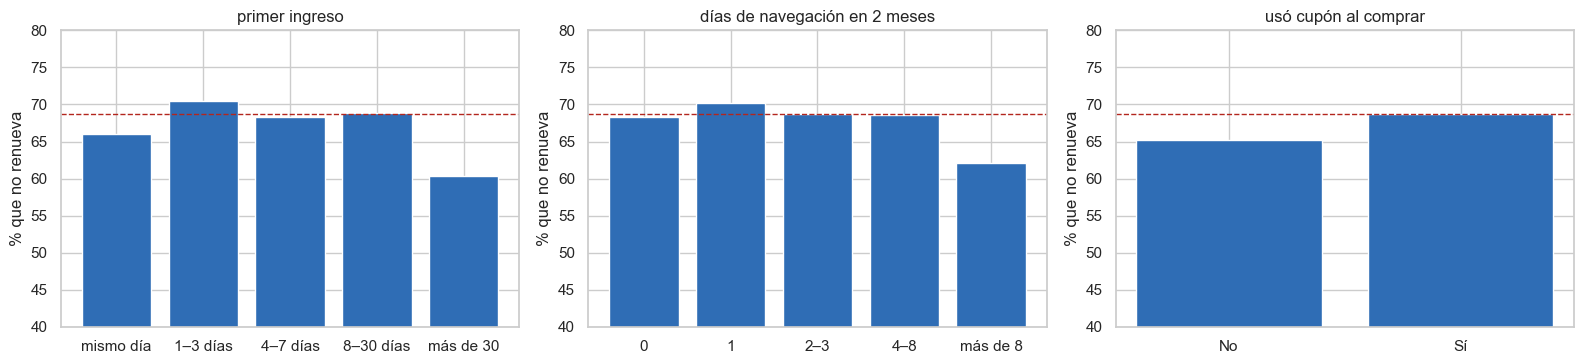

,mean,size
días de navegación en 2 meses,,
0,0.684,4165
1,0.702,851
2–3,0.687,1272
4–8,0.686,1653
más de 8,0.622,711


In [6]:
f = nuevas[["ciclo_id", "usuario_id", "ciclo_inicio", "churn90"]].merge(
    snap[["usuario_id", "fecha", "total_dias_navegacion_mes", "dias_hasta_primer_ingreso", "cantidad_cupones_aplicados", "valor_descuentos_cupones", "categoria_id"]], on="usuario_id")
f = f[(f["fecha"] >= f["ciclo_inicio"]) & (f["fecha"] <= f["ciclo_inicio"] + pd.Timedelta(days=75))].sort_values(["ciclo_id", "fecha"])
g = f.groupby("ciclo_id"); a = g.first(); a["nav_2m"] = g["total_dias_navegacion_mes"].sum()
a["primer ingreso"] = pd.cut(a["dias_hasta_primer_ingreso"], [-1, 0, 3, 7, 30, 10000], labels=["mismo día", "1–3 días", "4–7 días", "8–30 días", "más de 30"])
a["días de navegación en 2 meses"] = pd.cut(a["nav_2m"], [-1, 0, 1, 3, 8, 100], labels=["0", "1", "2–3", "4–8", "más de 8"])
a["usó cupón al comprar"] = np.where(a["cantidad_cupones_aplicados"] > 0, "Sí", "No")
print(f"Altas nuevas con fotos en sus primeros 75 días: {len(a):,} de {len(nuevas):,} ({len(a)/len(nuevas):.0%}); el resto empezó antes de 2024 o no tiene foto")
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
for axx, col in zip(ax, ["primer ingreso", "días de navegación en 2 meses", "usó cupón al comprar"]):
    t = a.groupby(col, observed=True)["churn90"].agg(["mean", "size"]); axx.bar(t.index.astype(str), t["mean"] * 100, color=AZUL)
    axx.axhline(nuevas["churn90"].mean() * 100, color=ROJO, ls="--", lw=1); axx.set_title(col); axx.set_ylabel("% que no renueva"); axx.set_ylim(40, 80)
plt.tight_layout(); plt.savefig(FIG / "nuevas_activacion.png", dpi=130); plt.show()
a.groupby("días de navegación en 2 meses", observed=True)["churn90"].agg(["mean", "size"]).round(3)

### 2.2 Descuento y categoría

In [7]:
a["descuento al comprar"] = pd.qcut(a["valor_descuentos_cupones"].where(a["valor_descuentos_cupones"] > 0), 4, labels=["menor", "medio-bajo", "medio-alto", "mayor"])
a["categoria"] = a["categoria_id"].map({1: "Básica", 2: "Oro", 3: "Platino"})
print(a.groupby("descuento al comprar", observed=True)["churn90"].agg(["mean", "size"]).round(3))
print(a.groupby("categoria", observed=True)["churn90"].agg(["mean", "size"]).round(3))

                       mean  size
descuento al comprar             
menor                 0.716  1948
medio-bajo            0.736  2041
medio-alto            0.650  1732
mayor                 0.625  1548
            mean  size
categoria             
Básica     0.727   194
Oro        0.715  5642
Platino    0.611  2816


### 2.3 Lo que estos datos permiten (y no permiten) concluir
Las tablas anteriores **describen** quién se va y en qué circunstancias, pero no explican **por qué**: para eso faltan el motivo de compra, el motivo de salida, el precio pagado y el canal de venta. Las hipótesis generales sobre por qué se compra y por qué se va, con su evidencia a favor, en contra y la forma de comprobarlas, están en las conclusiones de este notebook (sección 4).

### 2.4 Comparación entre planes
El producto `237480` es el plan **Básica**, `91113` es **Oro** y `237481` es **Platino**. Se comparan los tres en cómo se usan, si se compran con descuento, si el uso cambia el churn dentro de cada plan y qué pasa con quienes se van.

In [8]:
NOMBRE = {"237480": "Básica", "91113": "Oro", "237481": "Platino"}
m = ciclos[ciclos["madura"] & ciclos["productoid"].isin(NOMBRE)].copy(); m["plan"] = m["productoid"].map(NOMBRE)
f = m[["ciclo_id", "usuario_id", "ciclo_inicio", "ciclo_fin"]].merge(
    snap[["usuario_id", "fecha", "total_dias_navegacion_mes", "cantidad_cupones_aplicados", "valor_descuentos_cupones"]], on="usuario_id")
f = f[(f["fecha"] >= f["ciclo_inicio"]) & (f["fecha"] <= f["ciclo_fin"])]
uso = f.groupby("ciclo_id").agg(nav=("total_dias_navegacion_mes", "mean"), con_cupon=("cantidad_cupones_aplicados", lambda x: (x > 0).mean()),
                                descuento=("valor_descuentos_cupones", "mean"))
m = m.join(uso, on="ciclo_id")
perfil = m.groupby("plan").agg(ciclos=("churn90", "size"), churn=("churn90", "mean"), pct_altas_nuevas=("tipo_entrada", lambda x: (x == "NUEVA").mean()),
                               dias_navegacion_mes=("nav", "mean"), pct_con_cupon=("con_cupon", "mean"), descuento_promedio=("descuento", "mean")).round(3)
display(perfil.loc[["Básica", "Oro", "Platino"]])

m["uso"] = pd.cut(m["nav"], [-1, 0, 1, 3, 100], labels=["sin uso", "hasta 1 día", "1 a 3 días", "más de 3"])
print("Churn según el uso del ciclo, dentro de cada plan:")
m.pivot_table(index="uso", columns="plan", values="churn90", aggfunc="mean", observed=True)[["Básica", "Oro", "Platino"]].round(3)

,ciclos,churn,pct_altas_nuevas,dias_navegacion_mes,pct_con_cupon,descuento_promedio
plan,,,,,,
Básica,10292,0.806,0.499,0.185,0.014,2832.004
Oro,44225,0.473,0.265,0.812,0.079,22115.475
Platino,19787,0.384,0.266,1.214,0.085,59649.511


Churn según el uso del ciclo, dentro de cada plan:


plan,Básica,Oro,Platino
uso,,,
sin uso,0.814,0.493,0.395
hasta 1 día,0.714,0.513,0.445
1 a 3 días,0.633,0.448,0.397
más de 3,0.600,0.413,0.346


### 2.5 ¿Los que se van vuelven?
Entre los ciclos cuyo resultado se conoce con al menos un año de seguimiento, se mide qué porcentaje de quienes se fueron (más de 90 días sin renovar) vuelve a tomar un plan principal en los siguientes 15 meses, a cuál plan y en qué mes.

,se fueron,vuelven en ≤ 15 meses,% que vuelve
plan,,,
Básica,8123,2601,0.320
Oro,15856,4138,0.261
Platino,4993,1092,0.219


A qué plan vuelven los que se fueron de Básica: {'Oro': 0.93, 'Platino': 0.04, 'Básica': 0.02, 'otro': 0.0}


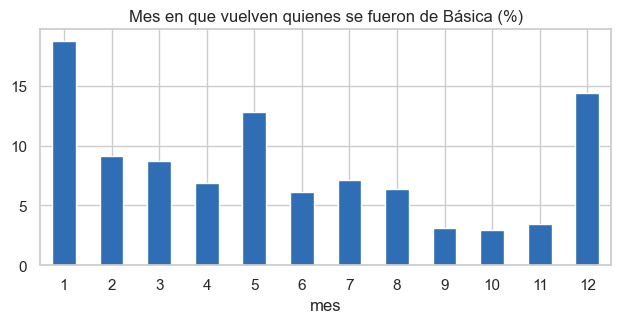

In [9]:
salen = m[(m["churn90"] == 1) & (m["ciclo_fin"] <= "2025-10-31")][["ciclo_id", "usuario_id", "ciclo_fin", "plan"]].copy()
princ = ciclos[ciclos["grupo_producto"] == "Principal"][["usuario_id", "ciclo_inicio", "productoid"]].rename(columns={"ciclo_inicio": "inicio_vuelta", "productoid": "plan_vuelta"})
v = salen.merge(princ, on="usuario_id"); v = v[v["inicio_vuelta"] > v["ciclo_fin"] + pd.Timedelta(days=90)].sort_values("inicio_vuelta").drop_duplicates("ciclo_id")
v["dias_fuera"] = (v["inicio_vuelta"] - v["ciclo_fin"]).dt.days; v = v[v["dias_fuera"] <= 455]
vuelve = pd.DataFrame({"se fueron": salen.groupby("plan").size(), "vuelven en ≤ 15 meses": v.groupby("plan").size()})
vuelve["% que vuelve"] = (vuelve["vuelven en ≤ 15 meses"] / vuelve["se fueron"]).round(3)
display(vuelve.loc[["Básica", "Oro", "Platino"]])
dest = v[v["plan"] == "Básica"]["plan_vuelta"].map(lambda z: NOMBRE.get(z, "otro")).value_counts(normalize=True).round(2)
print("A qué plan vuelven los que se fueron de Básica:", dest.to_dict())
mes = v[v["plan"] == "Básica"]["inicio_vuelta"].dt.month.value_counts(normalize=True).sort_index()
fig, ax = plt.subplots(figsize=(6.5, 3.4)); (mes * 100).plot.bar(ax=ax, color=AZUL); ax.set_title("Mes en que vuelven quienes se fueron de Básica (%)"); ax.set_xlabel("mes"); ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.savefig(FIG / "basica_regresos.png", dpi=130); plt.show()

## 3. Registro de lo que se intentó
| Intento | Resultado | Decisión |
|---|---|---|
| Etiqueta derivada solo del KPI | El KPI solo guarda suscriptores activos y no permite saber quién renovó | Se integran las órdenes como fuente de verdad del ciclo y la renovación |
| Excluir regalos y planes cortos | Dinámica distinta; subieron a 34 % de los ciclos en el tercer trimestre de 2026 | Fuera del modelo, análisis aparte |
| Excluir a quienes ya pagaron la renovación | Quita ventaja artificial (sección 1.3) | Se mantiene la exclusión |
| Comportamiento del ciclo + historial previo | +0,03 de AUC sobre el contexto | Se mantiene |
| Historia de 12 meses (uso de 6 meses vs. previos, cupones, compras) | +0,00 a +0,03, irregular | Se mantiene |
| Ponderar más los ciclos recientes | Mejora en unos horizontes y empeora en otros | Se descarta |
| Afinar hiperparámetros, validación cruzada temporal, poda de variables, mezclas | Ver notebook 06: gana en validación, no en la prueba; el poder queda en 0,64–0,67 (validación) y 0,67–0,71 (prueba) | Se mantiene el boosting con variables podadas |
| Cinco algoritmos de clase | Regresión logística, KNN y SVM ≈ 0,58–0,59; árbol 0,61–0,64; boosting 0,67 | Boosting |
| Recalibración isotónica y de Platt | No corrige el cambio de nivel (deriva), conserva el orden | Platt y niveles por ranking; churn esperado = churn real del nivel |
| Contacto comercial como variable | Solo existe desde feb-2026; no se puede aprender | Solo descriptivo |
| Segmentos de comportamiento (K-Means, mezcla gaussiana, jerárquico) | Estables; silueta 0,22 con 16 variables y 0,39 con 5 variables (notebook 04) | Para explicar, no para predecir |

## 4. Conclusiones de la etapa

### ¿Hay un techo? Sí, pero es de información, no de algoritmo
- **Cinco algoritmos distintos convergen** en el mismo rango (el mejor, boosting, llega a ROC-AUC 0,67–0,70; los demás quedan por debajo). Cambiar de algoritmo no es el camino.
- **Cada capa de información suma lo mismo, unos +0,03 de AUC**: tipo de entrada y producto (0,59), historial del ciclo (0,62), cómo pagó antes (0,65) y comportamiento de uso (0,68). Es decir, el comportamiento en la plataforma explica una parte, pero no es dominante: sigue faltando lo que más pesa en una decisión de compra (precio realmente pagado, motivo de compra, motivo de salida).
- **Más datos ayudan despacio, no de golpe:** pasar de 10 % a 100 % del entrenamiento sube el AUC de 0,64 a 0,68, con ruido. Como el KPI solo existe desde 2024, el modelo mejorará de forma gradual a medida que se acumulen meses.
- **El pago anticipado puede inflar un modelo:** si se incluye a quienes ya pagaron y se usa esa marca, el AUC a 1 mes sube a **0,81**; sin esa trampa es **0,70**. El modelo de este proyecto excluye a esos usuarios, por eso sus cifras son más bajas y más honestas.

### ¿Por qué se van los nuevos?
- **El plan pesa más que el uso.** El plan **Básica** (`237480`) concentra el 23 % de las altas nuevas y se va el **86 %** de ellas; Platino (`237481`) se va el 57 % y Oro (`91113`) el 66 %. Contando todos los ciclos: 81 %, 38 % y 47 %.
- **En el conjunto de altas nuevas el uso en los primeros dos meses casi no cambia el churn:** 0 días de navegación → 68 %, 2 a 8 días → 69 %, solo con más de 8 días baja a 62 %. Pero **dentro de cada plan sí hay gradiente**, sobre todo en Básica (sección 2.4): sin uso 81 %, más de 3 días 60 %. La mezcla de planes lo esconde en el promedio.
- **Descuento y categoría:** los que pagan más (mayor valor de descuento y Platino) se van menos (62 % y 61 %) que Oro y Básica (72 % y 73 %). Es coherente con que la decisión depende del tipo de cliente y del plan.
- **Temporada:** el churn de las altas varía poco por mes de alta (64 % a 74 %); no se ve una "estacionalidad de necesidad puntual" fuerte.

### Evidencia por plan (sin interpretar el plan)
Los tres planes principales se comportan distinto, y eso es un dato, no una hipótesis: Básica se va el 81 % (uso de 0,19 días al mes, 1,4 % con cupón), Oro el 47 % (0,81 días) y Platino el 38 % (1,21 días). En los tres, **más uso se asocia con menos churn** (en Básica de 81 % sin uso a 60 % con más de 3 días; en Oro de 49 % a 41 %; en Platino de 40 % a 35 %). Además, entre quienes se van, **vuelve a comprar entre el 22 % y el 32 % en los 15 meses siguientes** (la mayoría a Oro): parte de la salida es temporal.

### Hipótesis generales: por qué se compra y por qué se va
Los datos permiten **describir** qué pasa, no explicar por qué. Estas son las hipótesis que mejor encajan con lo observado; cada una indica qué la apoya, qué la debilita y qué dato o prueba la confirmaría. Son hipótesis de trabajo, no conclusiones.

**¿Por qué compran?**
| # | Hipótesis | Qué la apoya | Qué la debilita | Cómo comprobarla |
|---|---|---|---|---|
| C1 | **Necesidad puntual o estacional** (trámite, declaración, cambio normativo) | El 53 % de las altas nuevas ocurre entre enero y abril; los regresos se concentran en diciembre–enero | El churn de las altas de enero–febrero (64–65 %) no es mucho menor que el de otros meses | Preguntar el motivo de compra al registrarse |
| C2 | **Acceso por promoción, regalo o convenio** | En el tercer trimestre de 2026 los planes cortos y regalos pasan al 34 % de los ciclos | Solo el 3,5 % de los planes cortos pasa a un plan principal | Seguir la conversión de regalos cuando maduren; marcar el origen de la venta |
| C3 | **Probar antes de comprometerse** (planes de entrada) | Los planes de entrada reciben más altas nuevas y sus clientes vuelven más | Sin precio ni funciones por plan no se puede separar de otras causas | Medir el paso entre planes sin salir y ofrecer el salto antes del vencimiento |
| C4 | **Hábito o dependencia profesional** en quien ya renovó | Quien tiene al menos un ciclo previo se va 47–49 %, contra 66 % de quien no | Aun así casi la mitad se va | Cruzar con el tipo de cliente (contador independiente, firma, empresa) |

**¿Por qué se van?**
| # | Hipótesis | Qué la apoya | Qué la debilita | Cómo comprobarla |
|---|---|---|---|---|
| S1 | **Necesidad cumplida:** resolvieron lo que necesitaban y no ven razón para seguir | Los nuevos se van el 69 %; el uso por sí solo explica poco entre ellos | Es compatible con casi cualquier resultado | Encuesta de salida |
| S2 | **No encontraron valor / no se activaron** | Dentro de cada plan, más uso = menos churn; altas nuevas muy activas se van 60 % y sin uso 74 % | El efecto es moderado y quien usa mucho también se va (46 %) | Experimento de activación con grupo de control |
| S3 | **Sensibilidad al precio** | Los planes y descuentos de mayor valor se van menos (Platino 38 %) | No hay precio real por ciclo; puede ser el tipo de cliente y no el precio | Incorporar el precio pagado y probar precio o plan anual |
| S4 | **Cambio de circunstancia del cliente** (empleo, cartera de clientes) | Entre el 22 % y el 32 % de los que se van regresa dentro de 15 meses | No es observable | Preguntar al regreso qué cambió |
| S5 | **Alternativa o competencia** | No hay evidencia en los datos | No se mide | Encuesta de salida con opción "otra herramienta" |
| S6 | **Mala experiencia o soporte** | Pocos casos de soporte y relación muy débil con el churn (Spearman −0,03) | La experiencia no está bien registrada | Medir satisfacción o NPS al cierre del ciclo |

**Lo que sí se puede afirmar:** el churn es alto, se concentra en altas nuevas y en ciertos planes, se asocia con poco uso, y una cuarta parte o más de quienes se van regresa. **Lo que no se puede afirmar:** la causa. Para pasar de describir a explicar faltan cuatro datos: motivo de compra, motivo de salida, precio realmente pagado y canal de adquisición. Esa es la recomendación principal del proyecto.

### Preguntas que siguen abiertas y cómo responderlas
| Pregunta | Lo que dicen los datos hoy | Cómo se respondería |
|---|---|---|
| ¿Por qué se va tanto el plan de entrada (86 % de las altas nuevas)? | Poco uso, sin descuentos, y el 32 % vuelve (93 % a Oro) | Encuesta de salida y experimento de activación (tabla de hipótesis anterior) |
| ¿Se van por necesidad puntual? | El uso no explica el churn; la temporada de alta tampoco | Encuesta corta al momento de salir y cruce con la fecha de vencimiento tributario del cliente |
| ¿Contactar mejora la retención? | Los contactados se van menos en niveles medio y bajo, pero hay sesgo de selección | Experimento A/B con grupo de control |
| ¿El precio explica el churn? | Quien paga más se va menos | Incorporar el precio realmente pagado por ciclo |
| ¿Mejorará el modelo con el tiempo? | La curva de aprendizaje sube despacio | Reentrenar cada mes y vigilar el AUC mensual |